<a href="https://colab.research.google.com/github/gollapallyjessyjeevana21-maker/CODSOFT/blob/main/Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# Load the Customer Churn Dataset

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Step 4: Explore the Dataset

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Display the target column distribution
print("\nCustomer churn distribution:")
print(df["Churn"].value_counts())

Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [6]:
# Step 5: Data Preprocessing

# Create a copy of the dataset
data = df.copy()

# Remove customer ID because it is an identifier
data.drop("customerID", axis=1, inplace=True)

# Convert TotalCharges to numeric
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

# Convert the target column into numbers
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

# Separate input features and target
X = data.drop("Churn", axis=1)
y = data["Churn"]

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Preprocessing started successfully!")
print("Number of input features:", X.shape[1])
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("\nTarget distribution:")
print(y.value_counts())
print("\nMissing values in numerical features:")
print(X[numerical_features].isnull().sum())

Preprocessing started successfully!
Number of input features: 19
Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Missing values in numerical features:
SeniorCitizen      0
tenure             0
MonthlyCharges     0
TotalCharges      11
dtype: int64


In [7]:
# Step 6: Train-Test Split

from sklearn.model_selection import train_test_split

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train-test split completed successfully!")
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Train-test split completed successfully!
Training features shape: (5634, 19)
Testing features shape: (1409, 19)

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [8]:
# Step 7: Create Preprocessing Pipelines

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Pipeline for numerical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [9]:
# Step 8: Train Two Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the Logistic Regression model
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Create the Random Forest model
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train both models using the training data
logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [10]:
# Step 9: Five-Fold Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create five folds while preserving the target class proportions
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate Logistic Regression
logistic_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Evaluate Random Forest
random_forest_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Display the results
print("LOGISTIC REGRESSION")
print("ROC-AUC for each fold:", logistic_scores.round(4))
print("Mean ROC-AUC:", round(logistic_scores.mean(), 4))
print("Standard deviation:", round(logistic_scores.std(), 4))

print("\nRANDOM FOREST")
print("ROC-AUC for each fold:", random_forest_scores.round(4))
print("Mean ROC-AUC:", round(random_forest_scores.mean(), 4))
print("Standard deviation:", round(random_forest_scores.std(), 4))

LOGISTIC REGRESSION
ROC-AUC for each fold: [0.8479 0.8252 0.8419 0.8629 0.8529]
Mean ROC-AUC: 0.8461
Standard deviation: 0.0125

RANDOM FOREST
ROC-AUC for each fold: [0.8128 0.8015 0.8235 0.815  0.8384]
Mean ROC-AUC: 0.8182
Standard deviation: 0.0123


In [11]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
print(results_df.round(4).to_string(index=False))

MODEL PERFORMANCE COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8055     0.6572  0.5588    0.6040   0.8419
      Random Forest    0.7779     0.6034  0.4759    0.5321   0.8162


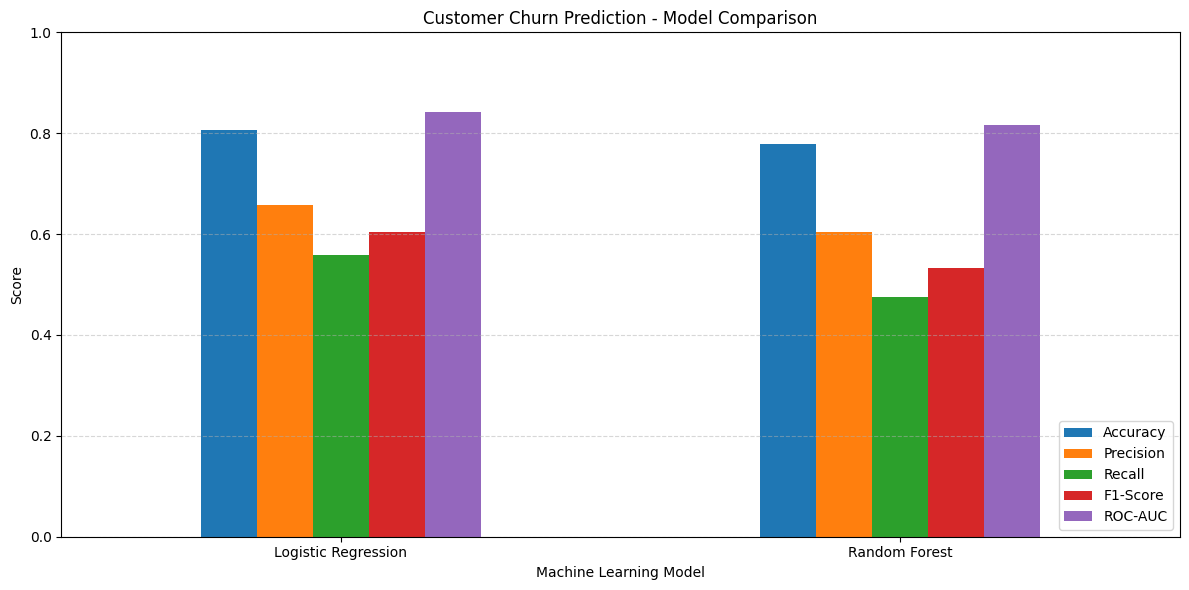

In [12]:
# Compare the performance of both models

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Customer Churn Prediction - Model Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

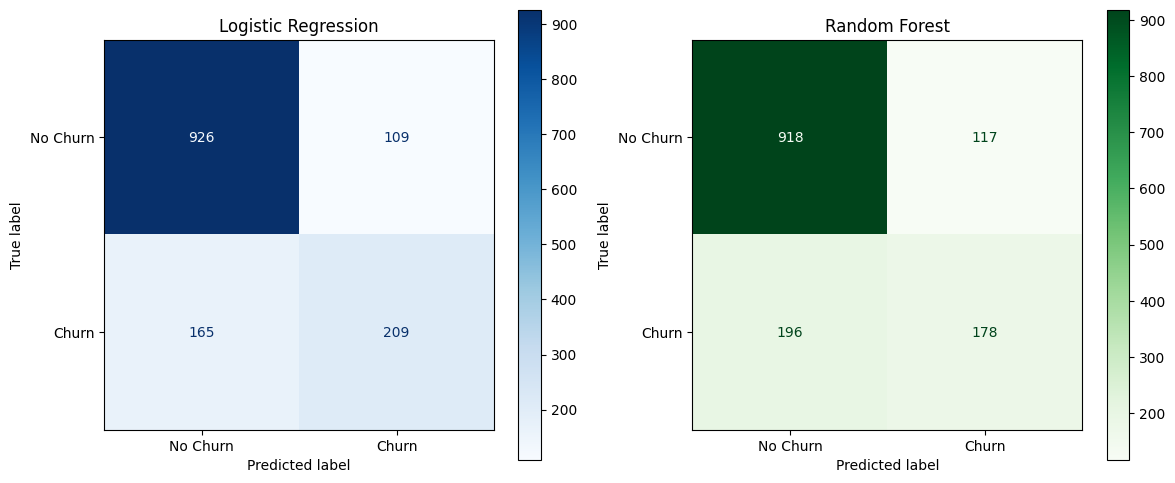

In [13]:
# Confusion matrices for both models

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_estimator(
    random_forest_model,
    X_test,
    y_test,
    display_labels=["No Churn", "Churn"],
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

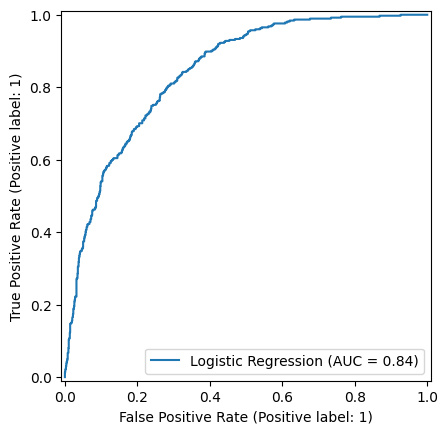

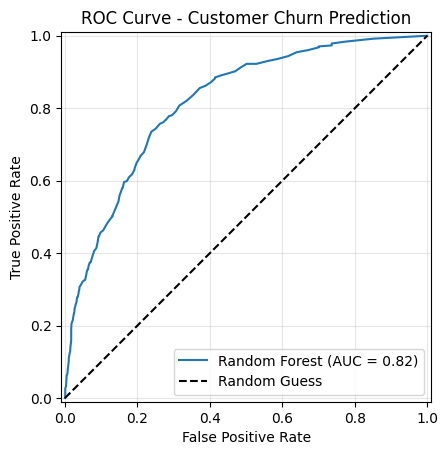

In [14]:
# ROC Curve Comparison

RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    name="Logistic Regression"
)

RocCurveDisplay.from_estimator(
    random_forest_model,
    X_test,
    y_test,
    name="Random Forest"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.title("ROC Curve - Customer Churn Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Customer Churn Prediction Using Machine Learning
1. Introduction
Customer churn occurs when customers stop using a company's services. Predicting churn helps businesses identify customers who may leave and take steps to improve customer retention.
2. Objective
The objective of this project is to develop and compare two supervised machine learning classification models to predict customer churn.
3. Dataset
The project uses the IBM Telco Customer Churn dataset. It contains customer information, service details, account information, and a target column indicating whether a customer left the company.
4. Data Preprocessing
The preprocessing steps include:
Removing the customer ID column.
Converting the TotalCharges column into a numeric format.
Handling missing values using imputation.
Encoding categorical features using one-hot encoding.
Scaling numerical features using standardization.
Splitting the dataset into training and testing sets using an 80:20 ratio.
5. Algorithms Used
Logistic Regression: A classification algorithm used to estimate the probability of a customer leaving.
Random Forest: An ensemble learning algorithm that combines multiple decision trees to make predictions.
6. Model Evaluation
Both models were evaluated using accuracy, precision, recall, F1-score, and ROC-AUC. Five-fold stratified cross-validation was also performed to compare model performance.
7. Results and Discussion
The results show that Logistic Regression achieved approximately 80% accuracy and a ROC-AUC of 0.84. Random Forest achieved approximately 78% accuracy and a ROC-AUC of 0.82.
Logistic Regression performed better on the reported test metrics. Its recall was also higher, meaning it identified more customers who actually churned than Random Forest at the default classification threshold.
8. Conclusion
This project demonstrates how machine learning can be used to predict customer churn. Among the two evaluated models, Logistic Regression performed better on the test results. In future work, the models could be improved through feature selection, hyperparameter tuning, and threshold optimization.